In [1]:
!pip install qiskit qiskit-aer pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 83.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 78.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


{'11': 471, '00': 529}
{'111': 509, '000': 491}
{'010': 477, '101': 523}


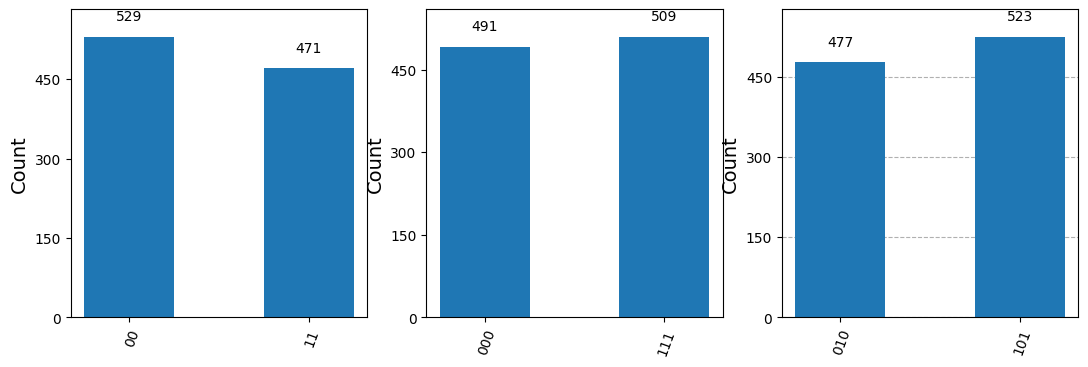

In [5]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = Aer.get_backend('qasm_simulator')
cir1 = QuantumCircuit(2, 2)
cir1.h(0)
cir1.cx(0,1)
cir1.measure([0,1], [0,1])
cont1 = sim.run(transpile(cir1, sim), shots=1000).result().get_counts()
print(cont1)
cir2 = QuantumCircuit(3, 3)
cir2.h(0)
cir2.cx(0, 1)
cir2.cx(1, 2)
cir2.measure([0, 1, 2], [0, 1, 2])
t2 = transpile(cir2, sim)
cont2 = sim.run(t2, shots=1000).result().get_counts()

cir3 = QuantumCircuit(3, 3)
cir3.h(0)
cir3.cx(0, 1)
cir3.cx(1, 2)
cir3.x(1)
cir3.measure([0, 1, 2], [0, 1, 2])
print(cont2)
job3 = sim.run(transpile(cir3, sim), shots=1000)
cont3 = job3.result().get_counts()
print(cont3)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
plot_histogram(cont1, ax=ax[0])
plot_histogram(cont2, ax=ax[1])
plot_histogram(cont3, ax=ax[2])
plt.show()

24790000000.0
25280938748.39303


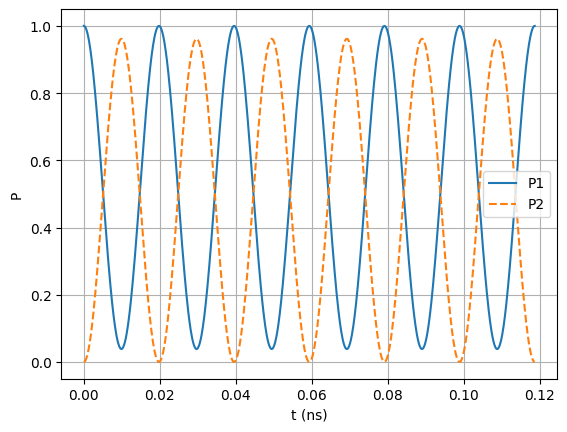

In [6]:
import numpy as np
import matplotlib.pyplot as plt

nu = 24.79e9
wr = nu
d = 0.2 * nu
w = np.sqrt(wr**2 + d**2)
w_rad = 2 * np.pi * w
print(wr)
print(w)

t = np.linspace(0, 3*(1/w), 1000)
p1 = np.cos(w_rad*t)**2 + (d/w)**2 * (np.sin(w_rad*t)**2)
p2 = (wr/w)**2 * (np.sin(w_rad*t)**2)
plt.plot(t*1e9, p1, label='P1')
plt.plot(t*1e9, p2, '--', label='P2')
plt.xlabel('t (ns)')
plt.ylabel('P')
plt.legend()
plt.grid()
plt.show()